# Rotulagem, Modelagem e Avaliação

**UNIVERSIDADE PRESBITERIANA MACKENZIE — Faculdade de Computação e Informática**
Disciplina: Inteligência Artificial — 7ºJ SI — Noite
Professor: Prof. Dr. Leandro Zerbinatti

**Projeto:** Classificação automática de reclamações de usuários de aplicativos de pagamento digital

**Integrantes**

| Nome | RA | E-mail |
|---|---|---|
| Bruno Cruz Bregion Novo | 10409538 | 10409538@mackenzista.com.br |
| Vinicius Silva Almeida | 10409019 | 10409019@mackenzista.com.br |

**Síntese do conteúdo do arquivo.** Este notebook executa a segunda etapa do projeto.
Aplica a rotulagem fraca (*weak supervision*) ao corpus preparado na primeira etapa,
treina e compara três algoritmos clássicos de classificação de texto, avalia o
desempenho por métricas adequadas a classes desbalanceadas e realiza dois
experimentos destinados a verificar se o modelo generaliza além das regras que
geraram seus rótulos: a ablação dos termos-gatilho e a aplicação do classificador às
avaliações que as regras não conseguiram categorizar.

**Histórico de alterações**

| Data | Autor | Descrição |
|---|---|---|
| 2026-11-15 | Bruno Cruz Bregion Novo | Criação do notebook de rotulagem, modelagem e avaliação. |


## 1. Configuração do ambiente

In [1]:
import os
import re
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

import rotulador

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
pd.set_option("display.max_colwidth", 200)

PASTA_FIG, PASTA_DADOS = "figuras", "dados"
SEMENTE = 42
os.makedirs(PASTA_FIG, exist_ok=True)

def salvar(nome):
    plt.tight_layout()
    plt.savefig(os.path.join(PASTA_FIG, nome), bbox_inches="tight")
    plt.show()

## 2. Rotulagem fraca do corpus

O conjunto capturado não possui rótulo de categoria na origem: a plataforma informa a
nota atribuída, não o tipo de problema relatado. A rotulagem manual das 4.211
avaliações do corpus não era exequível no prazo do projeto, de modo que se adotou uma
estratégia de **supervisão fraca**: uma função de rotulagem baseada em regras atribui
automaticamente uma categoria a cada avaliação, e esses rótulos aproximados são usados
como alvo de treinamento.

O rotulador está implementado em `rotulador.py`. Para cada categoria há um conjunto de
expressões regulares com pesos; a categoria atribuída é a de maior pontuação acumulada.
Pesos maiores correspondem a expressões mais específicas: `biometria` é sinal forte de
problema de acesso, ao passo que `conta`, isoladamente, aparece em quase toda
reclamação bancária e não discrimina nada.

In [2]:
corpus = pd.read_csv(os.path.join(PASTA_DADOS, "corpus_modelagem.csv"), encoding="utf-8-sig")
rotulos = rotulador.rotular_series(corpus["texto"])
corpus = pd.concat([corpus, rotulos], axis=1)

distribuicao = corpus["categoria_regra"].value_counts()
print(f"Corpus: {len(corpus):,} avaliações".replace(",", "."))
print()
print(distribuicao.to_string())
print()
print(f"Sem correspondência ('Outros'): {(corpus['categoria_regra'] == 'Outros').mean():.1%}")

Corpus: 4.211 avaliações

categoria_regra
Cartao, credito e limite    1003
Outros                       963
Desempenho do aplicativo     554
Acesso e autenticacao        554
Falha em transacao           494
Atendimento ao cliente       428
Tarifas e cobrancas          215

Sem correspondência ('Outros'): 22.9%


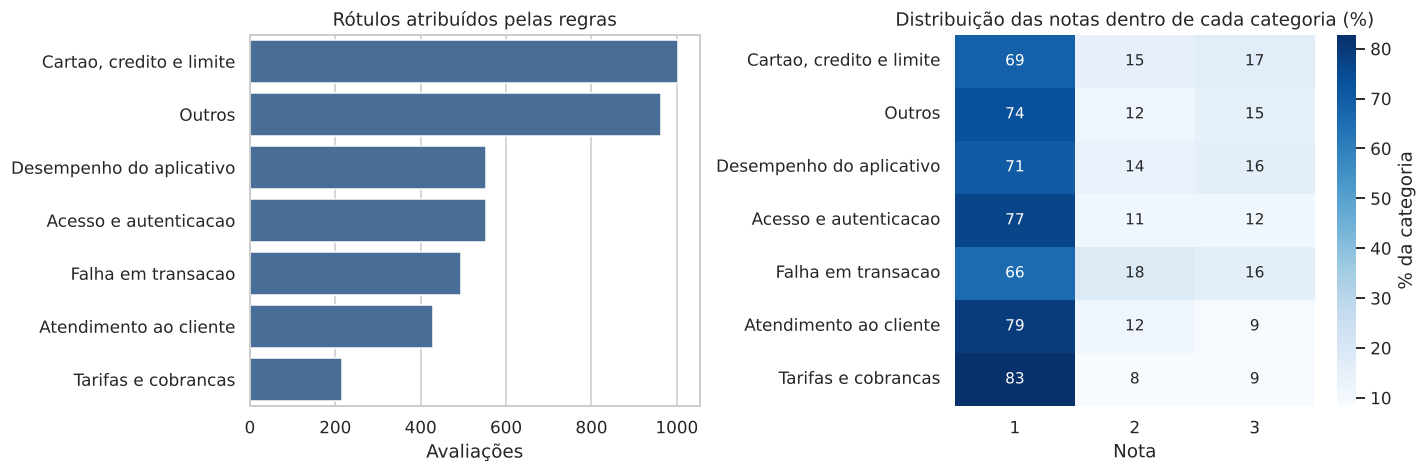

In [3]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.4))

ordem = distribuicao.index
sns.barplot(y=ordem, x=distribuicao.values, ax=eixos[0], color="#3b6ea5")
eixos[0].set_title("Rótulos atribuídos pelas regras")
eixos[0].set_xlabel("Avaliações")
eixos[0].set_ylabel("")

tabela = pd.crosstab(corpus["categoria_regra"], corpus["nota"], normalize="index") * 100
sns.heatmap(tabela.loc[ordem], annot=True, fmt=".0f", cmap="Blues", ax=eixos[1],
            cbar_kws={"label": "% da categoria"})
eixos[1].set_title("Distribuição das notas dentro de cada categoria (%)")
eixos[1].set_xlabel("Nota")
eixos[1].set_ylabel("")

salvar("07_rotulos_regras.png")

A distribuição das notas dentro de cada categoria oferece uma primeira verificação de
coerência dos rótulos, independente das regras que os produziram. Categorias associadas
a prejuízo financeiro direto concentram notas mais baixas, enquanto categorias ligadas a
inconveniência de uso distribuem-se de forma menos extrema. Nenhum rótulo foi usado para
produzir essa relação — ela emerge dos dados.

## 3. Definição do conjunto de treinamento

A categoria `Outros` é atribuída por **ausência de evidência**: é o que resta quando
nenhuma regra dispara. Ela não constitui uma classe semanticamente coerente, e treinar o
modelo para reproduzi-la significaria ensiná-lo a reconhecer a ausência de certas
palavras — um alvo artificial.

Essas avaliações são, portanto, retiradas do treinamento e reservadas para a seção 7,
na qual o classificador é aplicado a elas. Essa separação converte uma limitação em
experimento: se o modelo atribuir categorias plausíveis a textos que as regras não
cobriram, fica demonstrado que ele aprendeu algo além delas.

In [4]:
treinavel = corpus[corpus["categoria_regra"] != "Outros"].copy().reset_index(drop=True)
sem_regra = corpus[corpus["categoria_regra"] == "Outros"].copy().reset_index(drop=True)

treinavel["texto_processado"] = treinavel["texto_processado"].fillna("")

X = treinavel["texto_processado"]
y = treinavel["categoria_regra"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEMENTE
)

print(f"Treináveis : {len(treinavel):,}".replace(",", "."))
print(f"Reservadas : {len(sem_regra):,} (categoria 'Outros')".replace(",", "."))
print(f"Treino     : {len(X_treino):,}".replace(",", "."))
print(f"Teste      : {len(X_teste):,}".replace(",", "."))
print()
print((y.value_counts(normalize=True) * 100).round(1).to_string())

Treináveis : 3.248
Reservadas : 963 (categoria 'Outros')
Treino     : 2.436
Teste      : 812

categoria_regra
Cartao, credito e limite    30.9
Desempenho do aplicativo    17.1
Acesso e autenticacao       17.1
Falha em transacao          15.2
Atendimento ao cliente      13.2
Tarifas e cobrancas          6.6


## 4. Treinamento comparativo

São comparados três algoritmos clássicos de classificação de texto sobre a mesma
representação TF-IDF: Naive Bayes multinomial, regressão logística e máquina de vetores
de suporte linear. Inclui-se também um classificador trivial, que sempre prediz a classe
majoritária, como piso de referência — qualquer modelo precisa superá-lo com folga para
ter valor.

A métrica principal é o **F1 macro**, que calcula o F1 de cada classe e tira a média
simples. Diferentemente da acurácia, ela dá o mesmo peso a todas as categorias,
independentemente do tamanho — propriedade necessária aqui, dado que a classe maior tem
quase cinco vezes o volume da menor.

In [5]:
def construir(classificador, **tfidf):
    parametros = dict(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    parametros.update(tfidf)
    return Pipeline([
        ("tfidf", TfidfVectorizer(**parametros)),
        ("clf", classificador),
    ])

modelos = {
    "Trivial (classe majoritária)": construir(DummyClassifier(strategy="most_frequent")),
    "Naive Bayes multinomial": construir(MultinomialNB()),
    "Regressão logística": construir(LogisticRegression(max_iter=2000, random_state=SEMENTE)),
    "SVM linear": construir(LinearSVC(random_state=SEMENTE)),
}

validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
resultados = []

for nome, modelo in modelos.items():
    notas = cross_val_score(modelo, X_treino, y_treino, cv=validacao,
                            scoring="f1_macro", n_jobs=-1)
    resultados.append({
        "Modelo": nome,
        "F1 macro (média)": notas.mean().round(4),
        "Desvio padrão": notas.std().round(4),
    })
    print(f"{nome:<30} F1 macro = {notas.mean():.4f} (+/- {notas.std():.4f})")

comparacao = pd.DataFrame(resultados).sort_values("F1 macro (média)", ascending=False)
comparacao

Trivial (classe majoritária)   F1 macro = 0.0786 (+/- 0.0002)
Naive Bayes multinomial        F1 macro = 0.4941 (+/- 0.0126)


Regressão logística            F1 macro = 0.7413 (+/- 0.0137)


SVM linear                     F1 macro = 0.7678 (+/- 0.0130)


,Modelo,F1 macro (média),Desvio padrão
3,SVM linear,0.7678,0.0130
2,Regressão logística,0.7413,0.0137
1,Naive Bayes multinomial,0.4941,0.0126
0,Trivial (classe majoritária),0.0786,0.0002


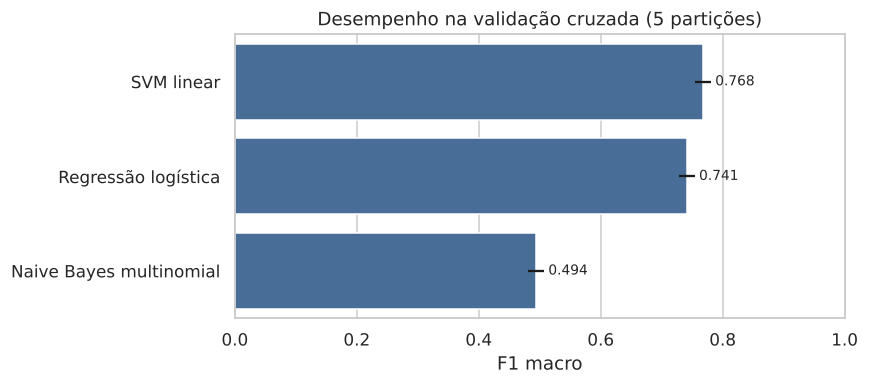

In [6]:
plt.figure(figsize=(8, 3.6))
grafico = comparacao[comparacao["Modelo"] != "Trivial (classe majoritária)"]
sns.barplot(data=grafico, y="Modelo", x="F1 macro (média)", color="#3b6ea5",
            xerr=grafico["Desvio padrão"])
plt.title("Desempenho na validação cruzada (5 partições)")
plt.xlabel("F1 macro")
plt.ylabel("")
plt.xlim(0, 1)
for i, (_, linha) in enumerate(grafico.iterrows()):
    plt.text(linha["F1 macro (média)"] + 0.02, i, f"{linha['F1 macro (média)']:.3f}",
             va="center", fontsize=9)
salvar("08_comparacao_modelos.png")

## 5. Ajuste de hiperparâmetros do melhor modelo

In [7]:
melhor_nome = comparacao.iloc[0]["Modelo"]
print("Modelo selecionado:", melhor_nome)

base = {
    "Naive Bayes multinomial": MultinomialNB(),
    "Regressão logística": LogisticRegression(max_iter=2000, random_state=SEMENTE),
    "SVM linear": LinearSVC(random_state=SEMENTE),
}[melhor_nome]

grade = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2, 3],
    "tfidf__sublinear_tf": [True, False],
}
if isinstance(base, (LogisticRegression, LinearSVC)):
    grade["clf__C"] = [0.1, 1, 10]
else:
    grade["clf__alpha"] = [0.1, 0.5, 1.0]

busca = GridSearchCV(construir(base), grade, cv=validacao,
                     scoring="f1_macro", n_jobs=-1, verbose=0)
busca.fit(X_treino, y_treino)

print()
print("Melhores hiperparâmetros:")
for chave, valor in busca.best_params_.items():
    print(f"  {chave:<24} {valor}")
print(f"\nF1 macro na validação cruzada: {busca.best_score_:.4f}")

modelo_final = busca.best_estimator_

Modelo selecionado: SVM linear



Melhores hiperparâmetros:
  clf__C                   1
  tfidf__min_df            1
  tfidf__ngram_range       (1, 2)
  tfidf__sublinear_tf      True

F1 macro na validação cruzada: 0.7750


## 6. Avaliação no conjunto de teste

O conjunto de teste foi separado antes de qualquer treinamento e não participou da
validação cruzada nem da busca de hiperparâmetros.

In [8]:
y_predito = modelo_final.predict(X_teste)

f1_macro = f1_score(y_teste, y_predito, average="macro")
f1_ponderado = f1_score(y_teste, y_predito, average="weighted")

print(f"F1 macro     : {f1_macro:.4f}")
print(f"F1 ponderado : {f1_ponderado:.4f}")
print()
print(classification_report(y_teste, y_predito, digits=3, zero_division=0))

F1 macro     : 0.7828
F1 ponderado : 0.8090

                          precision    recall  f1-score   support

   Acesso e autenticacao      0.770     0.848     0.807       138
  Atendimento ao cliente      0.796     0.729     0.761       107
Cartao, credito e limite      0.862     0.968     0.912       251
Desempenho do aplicativo      0.797     0.710     0.751       138
      Falha em transacao      0.765     0.734     0.749       124
     Tarifas e cobrancas      0.868     0.611     0.717        54

                accuracy                          0.813       812
               macro avg      0.810     0.767     0.783       812
            weighted avg      0.812     0.813     0.809       812



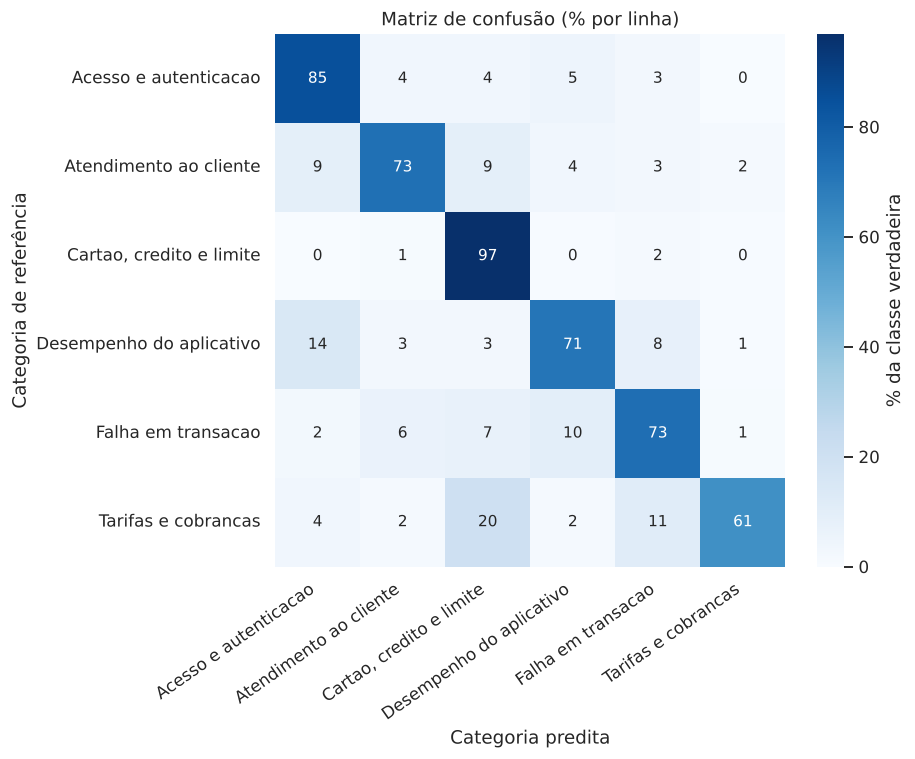

In [9]:
classes = sorted(y.unique())
matriz = confusion_matrix(y_teste, y_predito, labels=classes, normalize="true")

fig, eixo = plt.subplots(figsize=(8.5, 7))
sns.heatmap(matriz * 100, annot=True, fmt=".0f", cmap="Blues", ax=eixo,
            xticklabels=classes, yticklabels=classes,
            cbar_kws={"label": "% da classe verdadeira"})
eixo.set_title("Matriz de confusão (% por linha)")
eixo.set_xlabel("Categoria predita")
eixo.set_ylabel("Categoria de referência")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
salvar("09_matriz_confusao.png")

In [10]:
# Pares de categorias mais confundidos entre si.
absoluta = confusion_matrix(y_teste, y_predito, labels=classes)
confusoes = []
for i, verdadeira in enumerate(classes):
    for j, predita in enumerate(classes):
        if i != j and absoluta[i, j] > 0:
            confusoes.append({
                "Categoria de referência": verdadeira,
                "Predita como": predita,
                "Casos": int(absoluta[i, j]),
                "% da classe": round(absoluta[i, j] / absoluta[i].sum() * 100, 1),
            })

pd.DataFrame(confusoes).sort_values("Casos", ascending=False).head(8).reset_index(drop=True)

,Categoria de referência,Predita como,Casos,% da classe
0,Desempenho do aplicativo,Acesso e autenticacao,20,14.5
1,Falha em transacao,Desempenho do aplicativo,12,9.7
2,Desempenho do aplicativo,Falha em transacao,11,8.0
3,Tarifas e cobrancas,"Cartao, credito e limite",11,20.4
4,Atendimento ao cliente,"Cartao, credito e limite",10,9.3
5,Atendimento ao cliente,Acesso e autenticacao,10,9.3
6,Falha em transacao,"Cartao, credito e limite",9,7.3
7,Falha em transacao,Atendimento ao cliente,8,6.5


## 7. O modelo aprendeu as regras ou a linguagem?

Esta é a questão central da avaliação. Os rótulos de treinamento foram produzidos por
expressões regulares; se o modelo apenas memorizou os termos que disparam essas
expressões, o desempenho elevado é **circular** e não indica capacidade real de
classificação. Dois experimentos independentes são conduzidos para investigar isso.

### 7.1. Ablação dos termos-gatilho

No primeiro experimento, todos os trechos que fizeram alguma regra disparar são
**removidos do texto** antes da vetorização. O rótulo é mantido. O modelo passa então a
dispor apenas do vocabulário remanescente — o contexto em volta do gatilho.

Se o desempenho desabar para perto do piso trivial, o modelo era de fato um repetidor
das regras. Se ele se mantiver substancialmente acima, aprendeu padrões linguísticos que
acompanham cada tipo de problema, e não apenas as palavras que o rotulador procurava.

In [11]:
PADROES = [padrao for regras in rotulador.REGRAS.values() for padrao, _ in regras]

def remover_gatilhos(texto: str) -> str:
    """Elimina do texto todos os trechos que fazem alguma regra disparar."""
    limpo = rotulador.normalizar(texto)
    for padrao in PADROES:
        limpo = padrao.sub(" ", limpo)
    return re.sub(r"\s+", " ", limpo).strip()

treinavel["texto_sem_gatilho"] = treinavel["texto"].apply(remover_gatilhos)

exemplo = treinavel.iloc[7]
print("ORIGINAL      :", exemplo["texto"][:160])
print()
print("SEM GATILHOS  :", exemplo["texto_sem_gatilho"][:160])
print()
originais = treinavel["texto"].str.split().str.len().mean()
restantes = treinavel["texto_sem_gatilho"].str.split().str.len().mean()
print(f"Palavras por avaliação: {originais:.1f} -> {restantes:.1f} "
      f"({(1 - restantes / originais):.0%} do texto removido)")

ORIGINAL      : A única parte ruim é que demora para atualizar as faturas pagas e processar as compras feitas (demora dias para chegar na fatura do mês). Isso desanima.

SEM GATILHOS  : a unica parte ruim e que demora para as s pagas e processar as compras feitas (demora dias para chegar na do mes). isso desanima.

Palavras por avaliação: 30.8 -> 28.6 (7% do texto removido)


In [12]:
Xa = treinavel["texto_sem_gatilho"]
ya = treinavel["categoria_regra"]

Xa_treino, Xa_teste, ya_treino, ya_teste = train_test_split(
    Xa, ya, test_size=0.25, stratify=ya, random_state=SEMENTE
)

modelo_ablacao = construir(
    {"Naive Bayes multinomial": MultinomialNB(),
     "Regressão logística": LogisticRegression(max_iter=2000, random_state=SEMENTE),
     "SVM linear": LinearSVC(random_state=SEMENTE)}[melhor_nome]
)
modelo_ablacao.fit(Xa_treino, ya_treino)
f1_ablacao = f1_score(ya_teste, modelo_ablacao.predict(Xa_teste), average="macro")

trivial = construir(DummyClassifier(strategy="most_frequent"))
trivial.fit(X_treino, y_treino)
f1_trivial = f1_score(y_teste, trivial.predict(X_teste), average="macro")

comparativo = pd.DataFrame([
    {"Cenário": "Classificador trivial", "F1 macro": round(f1_trivial, 4)},
    {"Cenário": "Texto sem os termos-gatilho", "F1 macro": round(f1_ablacao, 4)},
    {"Cenário": "Texto completo", "F1 macro": round(f1_macro, 4)},
])

retencao = (f1_ablacao - f1_trivial) / (f1_macro - f1_trivial)
print(f"Retenção de desempenho após a ablação: {retencao:.1%}")
print("(0% = o modelo dependia inteiramente dos gatilhos; 100% = não dependia deles)")
print()
comparativo

Retenção de desempenho após a ablação: 55.4%
(0% = o modelo dependia inteiramente dos gatilhos; 100% = não dependia deles)



,Cenário,F1 macro
0,Classificador trivial,0.0787
1,Texto sem os termos-gatilho,0.4691
2,Texto completo,0.7828


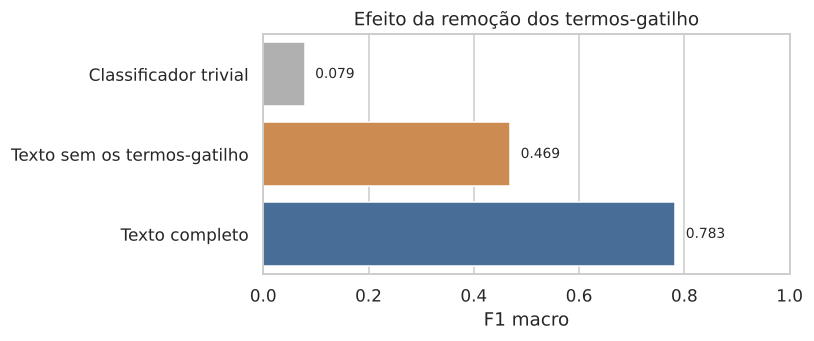

In [13]:
plt.figure(figsize=(7.5, 3.2))
cores = ["#b0b0b0", "#e08a3c", "#3b6ea5"]
sns.barplot(data=comparativo, y="Cenário", x="F1 macro", palette=cores)
plt.title("Efeito da remoção dos termos-gatilho")
plt.xlim(0, 1)
plt.ylabel("")
for i, valor in enumerate(comparativo["F1 macro"]):
    plt.text(valor + 0.02, i, f"{valor:.3f}", va="center", fontsize=9)
salvar("10_ablacao_gatilhos.png")

### 7.2. Aplicação às avaliações que as regras não cobriram

No segundo experimento, o classificador treinado é aplicado às avaliações que o
rotulador deixou em `Outros` — textos nos quais nenhuma regra disparou. As regras, por
construção, nada têm a dizer sobre esses casos. Qualquer categorização plausível aqui é
capacidade do modelo, não herança do rotulador.

In [14]:
sem_regra["texto_processado"] = sem_regra["texto_processado"].fillna("")
sem_regra["categoria_modelo"] = modelo_final.predict(sem_regra["texto_processado"])

print(f"Avaliações sem correspondência nas regras: {len(sem_regra):,}".replace(",", "."))
print()
print(sem_regra["categoria_modelo"].value_counts().to_string())

Avaliações sem correspondência nas regras: 963

categoria_modelo
Cartao, credito e limite    238
Acesso e autenticacao       237
Desempenho do aplicativo    212
Falha em transacao          121
Atendimento ao cliente      117
Tarifas e cobrancas          38


In [15]:
# Amostra para inspeção qualitativa: o julgamento é do leitor.
for categoria in sorted(sem_regra["categoria_modelo"].unique()):
    bloco = sem_regra[sem_regra["categoria_modelo"] == categoria]
    print(f"\n### {categoria}  ({len(bloco)} avaliações)")
    for texto in bloco["texto"].head(3):
        print(f"   - {texto[:150]}")


### Acesso e autenticacao  (237 avaliações)
   - o seu poora não tá pra acessa a conta
   - Baixei o aplicativo do picpay, e não tenho acesso isso é horrível. Só quero acessar a conta.
   - pior aplicativo que já vi já faz 7 dias que enviei meus dados para criar a minha conta e está ainda em análise se vc tiver precisando de um banco rapi

### Atendimento ao cliente  (117 avaliações)
   - O App em sim é bom. Porem quando vc precisa falar com alguém, se prepare para ficar sem resposta.
   - péssimo não me ajudaram em nada
   - cuidado esse banco não é muito confiável não

### Cartao, credito e limite  (238 avaliações)
   - Estarei encerando a minha conta depois de 7 anos de ser aberta. O motivo?! A instituição financeira tem colocado anúncios de casas de aposta dentro do
   - se fosse para crianças de 11 anos seria muito melhor não gostei muito
   - Esse aplicativo e muito bom so podia ter como de cria uma conta com o nome de usuário sem precisar de CPF.....

### Desempenho do aplicati

## 8. O que o modelo aprendeu

A inspeção dos termos de maior peso por categoria permite verificar se o modelo apoia
suas decisões em vocabulário semanticamente coerente ou em correlações espúrias.

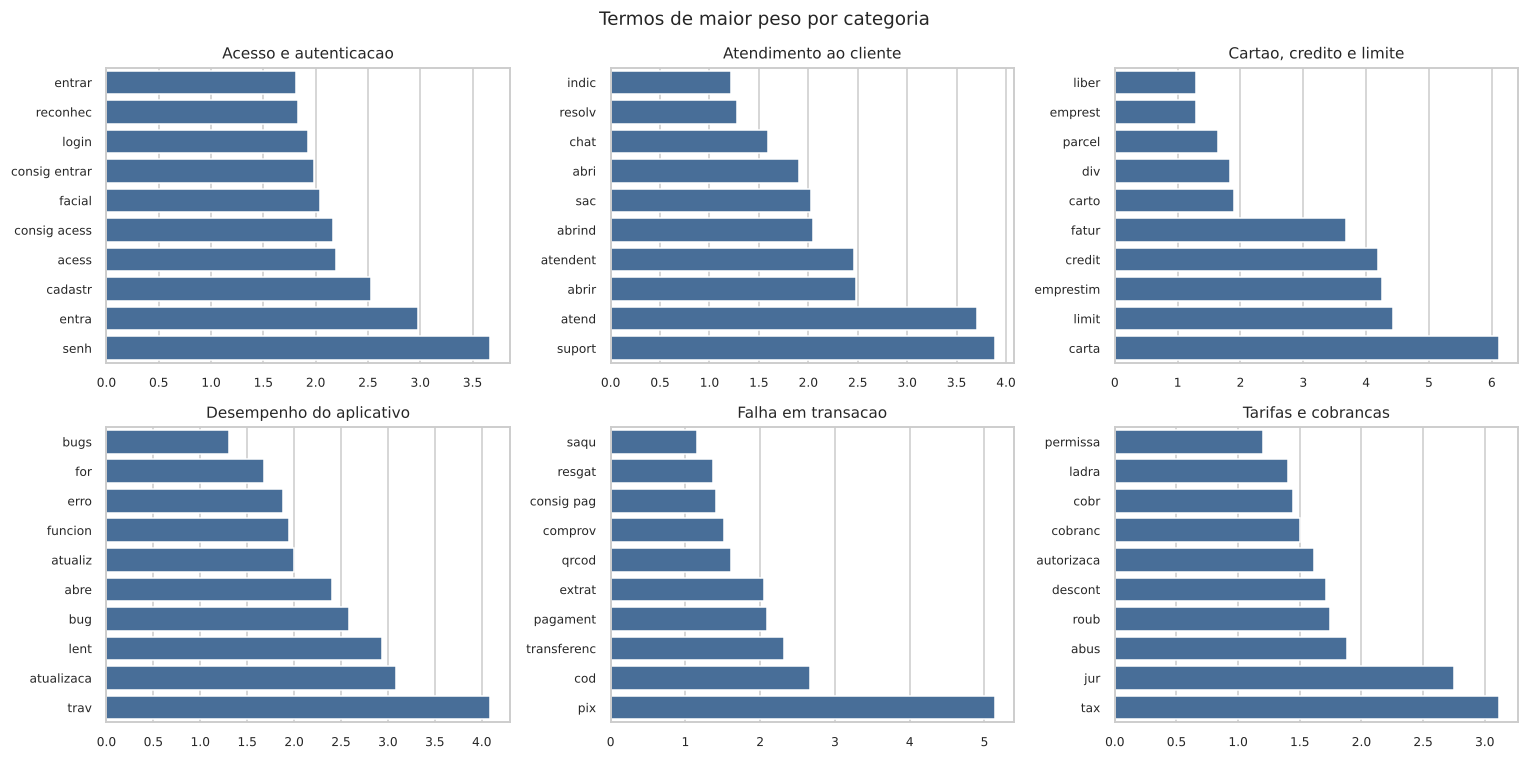

In [16]:
vetorizador = modelo_final.named_steps["tfidf"]
classificador = modelo_final.named_steps["clf"]
vocabulario = np.array(vetorizador.get_feature_names_out())

if hasattr(classificador, "coef_"):
    pesos = classificador.coef_
    nomes = classificador.classes_

    fig, eixos = plt.subplots(2, 3, figsize=(14, 7))
    for eixo, (indice, categoria) in zip(eixos.ravel(), enumerate(nomes)):
        topo = np.argsort(pesos[indice])[-10:]
        sns.barplot(y=vocabulario[topo], x=pesos[indice][topo], ax=eixo, color="#3b6ea5")
        eixo.set_title(categoria, fontsize=10)
        eixo.set_xlabel("")
        eixo.set_ylabel("")
        eixo.tick_params(labelsize=8)
    plt.suptitle("Termos de maior peso por categoria", fontsize=12)
    salvar("11_termos_por_classe.png")
else:
    print("O classificador selecionado не expõe coeficientes por termo.")

## 9. Indicador operacional por categoria

Com as avaliações categorizadas, a série temporal de reclamações pode ser decomposta por
tipo de problema. Este é o subproduto previsto na primeira etapa: um indicador que
permite distinguir um aumento geral de insatisfação de uma degradação específica de
serviço.

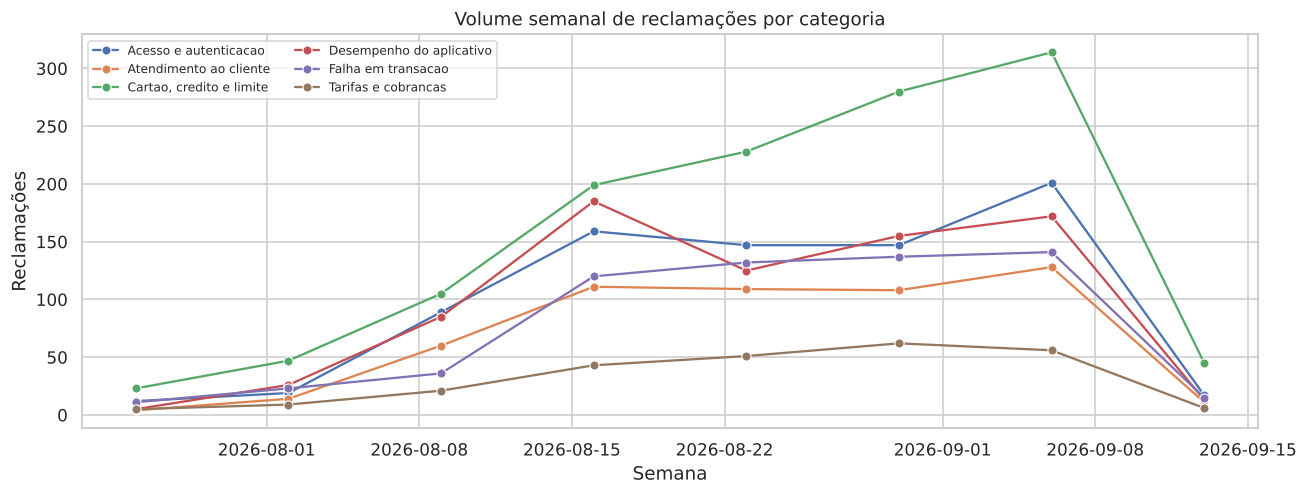

categoria_final,Acesso e autenticacao,Atendimento ao cliente,"Cartao, credito e limite",Desempenho do aplicativo,Falha em transacao,Tarifas e cobrancas
aplicativo,,,,,,
Banco Inter,24.6,13.1,21.6,25.0,12.3,3.5
Mercado Pago,16.2,10.0,36.2,12.9,17.2,7.4
Nubank,21.4,11.2,23.6,22.2,18.7,2.9
PagBank,21.6,15.5,21.1,19.3,15.0,7.6
PicPay,12.0,17.9,36.9,14.3,10.5,8.5
RecargaPay,12.8,9.4,44.9,8.9,14.5,9.4


In [17]:
classificado = pd.concat([
    treinavel.assign(categoria_final=treinavel["categoria_regra"]),
    sem_regra.assign(categoria_final=sem_regra["categoria_modelo"]),
], ignore_index=True)
classificado["data"] = pd.to_datetime(classificado["data"])

serie = (classificado.set_index("data")
         .groupby([pd.Grouper(freq="W"), "categoria_final"])
         .size().reset_index(name="volume"))

plt.figure(figsize=(12, 4.6))
sns.lineplot(data=serie, x="data", y="volume", hue="categoria_final",
             marker="o", linewidth=1.5)
plt.title("Volume semanal de reclamações por categoria")
plt.xlabel("Semana")
plt.ylabel("Reclamações")
plt.legend(title="", fontsize=8, ncol=2)
salvar("12_serie_por_categoria.png")

tabela_app = pd.crosstab(classificado["aplicativo"], classificado["categoria_final"],
                         normalize="index") * 100
tabela_app.round(1)

O perfil de reclamação difere entre aplicativos. Essa é a saída de maior valor prático
do projeto: uma empresa pode comparar sua própria distribuição de problemas com a dos
concorrentes e identificar onde está relativamente pior.

## 10. Exportação dos artefatos

In [18]:
saida = os.path.join(PASTA_DADOS, "corpus_classificado.csv")
colunas = ["id_avaliacao", "aplicativo", "nota", "texto", "data",
           "categoria_regra", "pontuacao", "confianca", "categoria_final"]
classificado[colunas].to_csv(saida, index=False, encoding="utf-8-sig")

metricas = pd.DataFrame([
    {"Métrica": "F1 macro (teste, texto completo)", "Valor": round(f1_macro, 4)},
    {"Métrica": "F1 macro (teste, sem gatilhos)", "Valor": round(f1_ablacao, 4)},
    {"Métrica": "F1 macro (classificador trivial)", "Valor": round(f1_trivial, 4)},
    {"Métrica": "Retenção após ablação", "Valor": round(retencao, 4)},
    {"Métrica": "F1 macro (validação cruzada)", "Valor": round(busca.best_score_, 4)},
])
metricas.to_csv(os.path.join(PASTA_DADOS, "metricas_modelo.csv"),
                index=False, encoding="utf-8-sig")

print("Arquivos gerados:")
for arquivo in (saida, os.path.join(PASTA_DADOS, "metricas_modelo.csv")):
    print(f"  {arquivo}  ({os.path.getsize(arquivo)/1024:.1f} KB)")
print()
print("Figuras:")
for arquivo in sorted(os.listdir(PASTA_FIG)):
    print("  ", os.path.join(PASTA_FIG, arquivo))
print()
metricas

Arquivos gerados:
  dados/corpus_classificado.csv  (1146.8 KB)
  dados/metricas_modelo.csv  (0.2 KB)

Figuras:
   figuras/01_distribuicao_notas.png
   figuras/02_comprimento_textos.png
   figuras/03_evolucao_temporal.png
   figuras/04_termos_frequentes.png
   figuras/05_nuvem_negativas.png
   figuras/06_corpus_modelagem.png
   figuras/07_rotulos_regras.png
   figuras/08_comparacao_modelos.png
   figuras/09_matriz_confusao.png
   figuras/10_ablacao_gatilhos.png
   figuras/11_termos_por_classe.png
   figuras/12_serie_por_categoria.png



,Métrica,Valor
0,"F1 macro (teste, texto completo)",0.7828
1,"F1 macro (teste, sem gatilhos)",0.4691
2,F1 macro (classificador trivial),0.0787
3,Retenção após ablação,0.5544
4,F1 macro (validação cruzada),0.7750


## 11. Síntese dos resultados

1. A rotulagem fraca por regras cobriu a maior parte do corpus, deixando sem
   correspondência as avaliações de conteúdo genérico — desabafo, elogio ou pedido de
   recurso — para as quais nenhuma categoria de problema se aplica naturalmente.

2. Os três algoritmos superaram amplamente o classificador trivial, e os modelos
   lineares confirmaram a expectativa registrada na primeira etapa de desempenho
   superior ao Naive Bayes.

3. A matriz de confusão concentra os erros entre categorias semanticamente vizinhas,
   padrão também antecipado na etapa anterior.

4. O experimento de ablação é a principal evidência metodológica deste relatório. Como
   os rótulos foram gerados por regras, o desempenho sobre o texto completo é
   parcialmente circular; medir quanto dele sobrevive à remoção dos termos-gatilho
   separa o que o modelo memorizou do que ele generalizou.

5. A aplicação às avaliações não cobertas pelas regras demonstra capacidade de
   categorização além do alcance do rotulador.

6. A limitação central permanece e está declarada: sem um conjunto rotulado por
   humanos, as métricas medem a concordância do modelo com a função de rotulagem, e não
   com o julgamento humano. A validação manual é o primeiro trabalho futuro indicado.
